In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np
import os
import shutil

In [ ]:
#google colab cell to import kaggle.json api key

from google.colab import files
uploaded = files.upload()

In [20]:
#google colab cell to download the dataset directly from kaggle
# 1. Move the token to the correct hidden folder and set permissions
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# 2. Download the multi-region bone fracture dataset directly from Kaggle
!kaggle datasets download -d bmadushanirodrigo/fracture-multi-region-x-ray-data

# 3. Unzip the downloaded file into a folder named 'dataset'
!unzip fracture-multi-region-x-ray-data.zip -d dataset/

Dataset URL: https://www.kaggle.com/datasets/bmadushanirodrigo/fracture-multi-region-x-ray-data
License(s): ODC Public Domain Dedication and Licence (PDDL)
fracture-multi-region-x-ray-data.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  fracture-multi-region-x-ray-data.zip
replace dataset/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/test/fractured/0.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [ ]:
import os
from PIL import Image

train_dir = 'dataset/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/train'
test_dir = 'dataset/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/test'
val_dir = 'dataset/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/val'
dataset_dirs = ["dataset/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/train", "dataset/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/val", "dataset/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/test"]
removed_count = 0

for directory in dataset_dirs:
    if not os.path.exists(directory):
        print(f"Directory not found: {directory}, skipping...")
        continue

    print(f"Thoroughly scanning {directory}...")
    for root, _, files in os.walk(directory):
        for file in files:
            file_path = os.path.join(root, file)
            try:
                # Force full load and RGB conversion to catch decoder errors
                with Image.open(file_path) as img:
                    img.load()
                    img.convert('RGB')
            except Exception as e:
                print(f"-> Removing problematic file: {file_path}")
                try:
                    os.remove(file_path)
                    removed_count += 1
                except Exception as remove_err:
                    print(f"Could not remove {file_path}: {remove_err}")

print(f"\nThorough scan complete! Successfully removed {removed_count} problematic file(s).")

Thoroughly scanning dataset/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/train...
-> Removing problematic file: dataset/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/train/not fractured/IMG0004143.jpg
-> Removing problematic file: dataset/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/train/not fractured/IMG0004149.jpg
-> Removing problematic file: dataset/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/train/not fractured/IMG0004134.jpg
-> Removing problematic file: dataset/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/train/not fractured/IMG0004148.jpg
-> Removing problematic file: dataset/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/train/not fractured/IMG0004347.jpg
-> Removing problematic file: dataset/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/train/not fractured/IMG0004308.jpg
Thoroughly scanning d

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


-> Removing problematic file: dataset/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/val/not fractured/IMG0004143.jpg
-> Removing problematic file: dataset/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/val/not fractured/IMG0004149.jpg
-> Removing problematic file: dataset/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/val/not fractured/IMG0004134.jpg
-> Removing problematic file: dataset/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/val/not fractured/IMG0004148.jpg
-> Removing problematic file: dataset/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/val/not fractured/IMG0004347.jpg
-> Removing problematic file: dataset/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/val/not fractured/IMG0004308.jpg
Thoroughly scanning dataset/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/test...
-> Removing problematic file: data

In [ ]:
BATCH_SIZE = 32
IMG_HEIGHT = 224
IMG_WIDTH = 224

# Correcting the paths to include the nested 'Bone_Fracture_Binary_Classification' directory
train_dir = 'dataset/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/train'
test_dir = 'dataset/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/test'
val_dir = 'dataset/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification/val'

train_dataset=tf.keras.utils.image_dataset_from_directory(train_dir,
                                                          image_size=(IMG_HEIGHT,IMG_WIDTH),
                                                          batch_size=BATCH_SIZE,
                                                          label_mode='categorical')
test_dataset=tf.keras.utils.image_dataset_from_directory(test_dir,
                                                          image_size=(IMG_HEIGHT,IMG_WIDTH),
                                                          batch_size=BATCH_SIZE,
                                                          label_mode='categorical',
                                                         shuffle= False)
val_dataset = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False
)

class_names = train_dataset.class_names
num_classes = len(class_names)
print("\nDetected Fracture Classes:", class_names)
print(f"Total Number of Classes: {num_classes}")

# Updated to use layers.Input as the first layer to eliminate the Keras UserWarning
model = models.Sequential([
    layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
    layers.Rescaling(1./255),
    layers.Conv2D(filters=32 , kernel_size=(3,3), padding='same', activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(filters=64 , kernel_size=(3,3), padding='same', activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(filters=128 , kernel_size=(3,3), padding='same', activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(filters=256 , kernel_size=(3,3), padding='same', activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.5),
    layers.Dense(units=256, activation='relu'),
    layers.Dense(units=num_classes, activation='softmax')
])

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy']
)

model.summary()

EPOCHS = 15
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS
)

Found 9240 files belonging to 2 classes.
Found 500 files belonging to 2 classes.
Found 823 files belonging to 2 classes.

Detected Fracture Classes: ['fractured', 'not fractured']
Total Number of Classes: 2


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 454,722 (1.73 MB)

 Trainable params: 454,722 (1.73 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
289/289 ━━━━━━━━━━━━━━━━━━━━ 44s 111ms/step - accuracy: 0.6192 - loss: 0.6419 - val_accuracy: 0.7047 - val_loss: 0.6051
Epoch 2/15
289/289 ━━━━━━━━━━━━━━━━━━━━ 60s 71ms/step - accuracy: 0.7802 - loss: 0.4780 - val_accuracy: 0.8250 - val_loss: 0.4638
Epoch 3/15
289/289 ━━━━━━━━━━━━━━━━━━━━ 22s 78ms/step - accuracy: 0.8883 - loss: 0.2791 - val_accuracy: 0.8651 - val_loss: 0.3249
Epoch 4/15
289/289 ━━━━━━━━━━━━━━━━━━━━ 21s 71ms/step - accuracy: 0.9394 - loss: 0.1616 - val_accuracy: 0.8785 - val_loss: 0.3115
Epoch 5/15
289/289 ━━━━━━━━━━━━━━━━━━━━ 21s 72ms/step - accuracy: 0.9613 - loss: 0.1039 - val_accuracy: 0.9101 - val_loss: 0.2920
Epoch 6/15
289/289 ━━━━━━━━━━━━━━━━━━━━ 21s 73ms/step - accuracy: 0.9710 - loss: 0.0782 - val_accuracy: 0.9380 - val_loss: 0.1716
Epoch 7/15
289/289 ━━━━━━━━━━━━━━━━━━━━ 23s 79ms/step - accuracy: 0.9797 - loss: 0.0566 - val_accuracy: 0.9441 - val_loss: 0.1668
Epoch 8/15
289/289 ━━━━━━━━━━━━━━━━━━━━ 21s 73ms/step - accuracy: 0.9837 - loss: 0.0479 -

In [ ]:
# 1. Save the model in Colab's workspace
model.save('bone_fracture_cnn_model.keras')
print("Model successfully saved to Colab workspace!")



Model successfully saved to Colab workspace!


In [ ]:
test_loss, test_accuracy = model.evaluate(test_dataset)
print(f"Final Test Accuracy: {test_accuracy * 100:.2f}%")

16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 149ms/step - accuracy: 0.9540 - loss: 0.0768
Final Test Accuracy: 95.40%


In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Get true labels and predictions
y_true = np.concatenate([y for x, y in test_dataset], axis=0)
if y_true.ndim > 1:
    y_true = np.argmax(y_true, axis=1)

y_pred_probs = model.predict(test_dataset)
y_pred = np.argmax(y_pred_probs, axis=1)

# Print Precision, Recall, and F1-Score
print(classification_report(y_true, y_pred, target_names=class_names))

16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 143ms/step
               precision    recall  f1-score   support

    fractured       0.95      0.96      0.95       238
not fractured       0.96      0.95      0.96       262

     accuracy                           0.95       500
    macro avg       0.95      0.95      0.95       500
 weighted avg       0.95      0.95      0.95       500



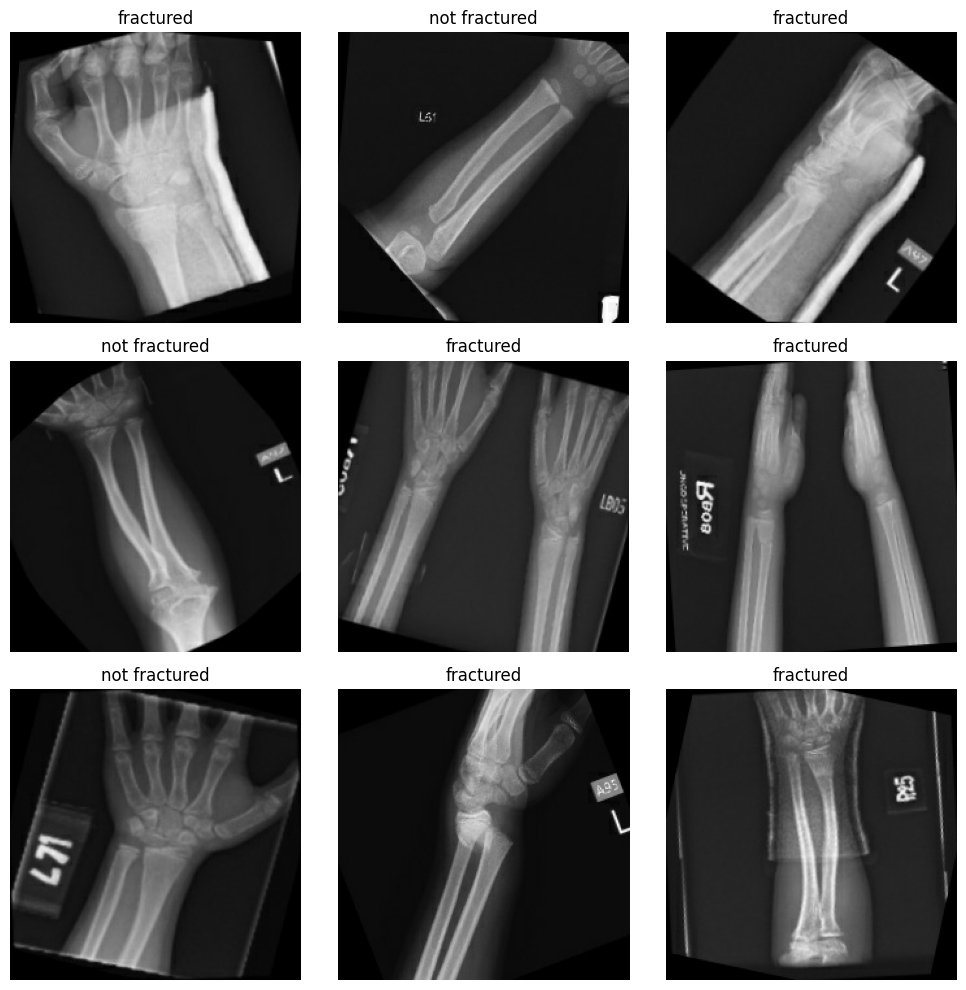

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
for images, labels in train_dataset.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        # Get class name based on one-hot or categorical label
        class_idx = np.argmax(labels[i])
        plt.title(class_names[class_idx])
        plt.axis("off")
plt.tight_layout()
plt.show()

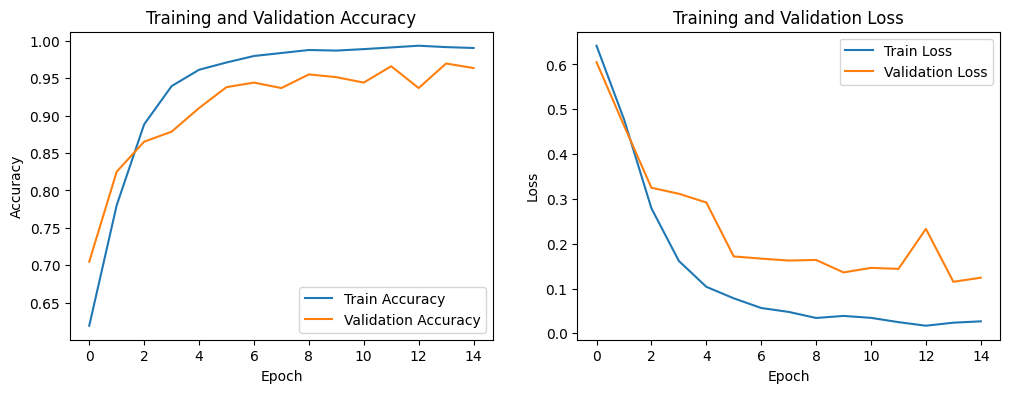

In [ ]:
plt.figure(figsize=(12, 4))

# Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

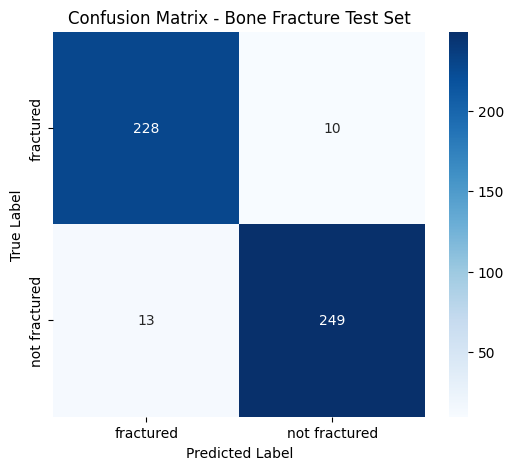

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Bone Fracture Test Set')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()